# 📊 Práctica 2 - Encargo 1: Determinación y Conciliación Forense de Ganancias por Región
### 🏛️ Arquitectura Híbrida: Extracción SQL Ligera (≤ 2 JOINs) + Transformación, Diagnóstico y Conciliación Contable en Memoria con Python & Pandas

---

### 🎯 Contexto y Reglas de Ingeniería del Proyecto
* **Base de Datos:** `northwind` (MySQL 8.0 desplegado en contenedor Docker, puerto `3308`).
* **Objetivo Principal:** Determinar las ganancias exactas por región de la compañía Northwind, documentando cada paso exploratorio, auditoría de discrepancias y decisiones tomadas hasta llegar al resultado definitivo.
* **⚠️ Restricción Estricta de Diseño:** 
  > **Ninguna consulta a SQL puede contener más de 2 `JOIN`s.**
  > **Estrategia Implementada:** Para cumplir estrictamente con esta restricción sin perder fidelidad analítica, se extraen las tablas completas en bruto (**0 JOINs**) o mediante consultas atómicas simples directamente hacia DataFrames de Pandas. Toda la lógica de álgebra relacional, detección y resolución de duplicidad cartesiana, normalización de campos, agrupaciones y conciliaciones contables se ejecuta en memoria mediante **Python & Pandas**.

---

### 🗺️ Hoja de Ruta Analítica (8 Fases Forenses)
1. **Fase 0:** Inicialización del Entorno, Conexión a la Base de Datos y Validador de Límites de JOINs.
2. **Fase 1:** Reconocimiento y Extracción en Bruto (*Data Discovery* - 0 JOINs).
3. **Fase 2:** Establecimiento de la Línea Base Contable (*Ground Truth Oficial*).
4. **Fase 3:** El Intento Ingenuo y la Gran Discrepancia (*Reproducción del Error Común en Pandas: +394.5%*).
5. **Fase 4:** Auditoría Forense y Diagnóstico de Causa Raíz (Multiplicidad N:M y Duplicación de Fletes).
6. **Fase 5:** Construcción de la Solución Robusta en Pandas (Desacoplamiento Empleado-Región).
7. **Fase 6:** Criterios de Negocio: Ventas Netas vs Facturación Integrada y Desglose por Vendedor.
8. **Fase 7:** *Master Table* Ejecutiva (KPIs Directivos Formateados).
9. **Fase 8:** Conciliación Contable Definitiva al Centavo ($0.00 de Discrepancia Certificada).
10. **Fase 9:** Tablero Visual de Métricas Gerenciales (Matplotlib & Seaborn).

In [1]:
# =============================================================================
# CONFIGURACIÓN INICIAL DEL ENTORNO DE TRABAJO
# =============================================================================
import os
import sys
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

# Configuración estética de Pandas para montos financieros y precisión
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)
pd.options.display.float_format = '${:,.2f}'.format

# Configuración de estilo de visualización para gráficos ejecutivos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

print("✅ Librerías importadas y entorno configurado correctamente.")

Matplotlib is building the font cache; this may take a moment.


✅ Librerías importadas y entorno configurado correctamente.


## 🔌 Fase 0: Inicialización del Motor de Base de Datos y Validador de JOINs

En esta fase establecemos la conexión con la base de datos `northwind` alojada en el contenedor MySQL 8.0 (puerto `3308`).

Para garantizar el cumplimiento de la restricción del encargo (*"las consultas no pueden tener más de dos joins"*), implementamos una función de validación estricta (`validate_max_joins`) que inspecciona sintácticamente cualquier consulta SQL antes de enviarla al motor relacional.

In [2]:
# =============================================================================
# MOTOR DE CONEXIÓN Y VALIDADOR DE RESTRICCIÓN DE JOINS
# =============================================================================

DB_HOST = os.getenv("MYSQL_HOST", "localhost")
DB_PORT = int(os.getenv("PRACTICA2_DB_PORT", "3308"))
DB_NAME = os.getenv("PRACTICA2_DB_NAME", "northwind")
DB_USER = os.getenv("PRACTICA2_DB_USER_ROOT", "root")
DB_PASS = os.getenv("PRACTICA2_DB_ROOT_PASSWORD", "rootpassword")

CONNECTION_URL = f"mysql+pymysql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}?charset=utf8mb4"
engine = create_engine(CONNECTION_URL, pool_pre_ping=True)

def validate_max_joins(sql_query: str, max_joins: int = 2) -> int:
    """
    Inspecciona la consulta SQL y asegura que no exceda el número máximo de JOINs permitido.
    Regla del requerimiento: Máximo 2 JOINs en SQL.
    """
    clean_sql = re.sub(r"--.*", "", sql_query)
    clean_sql = re.sub(r"/\*.*?\*/", "", clean_sql, flags=re.DOTALL)
    join_matches = re.findall(r"\b(?:INNER\s+|LEFT\s+|RIGHT\s+|CROSS\s+|FULL\s+)?JOIN\b", clean_sql, re.IGNORECASE)
    join_count = len(join_matches)
    
    if join_count > max_joins:
        raise ValueError(
            f"⚠️ VIOLACIÓN DE REGLA: La consulta contiene {join_count} JOINs, "
            f"pero el límite estricto establecido es de máximo {max_joins} JOINs.\n"
            f"Estrategia requerida: Extraiga las tablas a DataFrames de Pandas y procese en memoria."
        )
    return join_count

def extract_table(table_name: str) -> pd.DataFrame:
    """Extrae una tabla completa de MySQL hacia Pandas con exactamente 0 JOINs."""
    escaped_table = f"`{table_name}`" if not table_name.startswith("`") else table_name
    query = f"SELECT * FROM {escaped_table}"
    validate_max_joins(query, max_joins=2) # 0 JOINs <= 2 JOINs
    return pd.read_sql_query(query, con=engine)

# Probar conexión ejecutando un ping simple
with engine.connect() as conn:
    result = conn.execute(text("SELECT DATABASE(), VERSION(), NOW();")).fetchone()
    print(f"🎉 Conectado exitosamente a la base de datos '{result[0]}' (MySQL versión {result[1]}) en {result[2]}.")

🎉 Conectado exitosamente a la base de datos 'northwind' (MySQL versión 8.0.46) en 2026-10-28 04:00:18.


## 🔍 Fase 1: Reconocimiento y Extracción en Bruto (*Data Discovery* - 0 JOINs)

Un principio fundamental de la ingeniería de datos es **nunca realizar transformaciones a ciegas**.
Antes de modelar, debemos extraer y comprender la semántica de las 6 tablas esenciales del modelo de Northwind:

1. **`region`**: Catálogo de las 4 divisiones comerciales corporativas (Eastern, Westerns, Northern, Southern). Notar que la columna `RegionDescription` almacena espacios residuales de relleno (*trailing spaces*) provenientes de tipos `NCHAR(50)` de la base original, por lo que aplicamos `.str.strip()`.
2. **`territories`**: 53 territorios geográficos asignados a cada región (`RegionID`).
3. **`employeeterritories`**: Tabla puente N:M que asocia a los 9 vendedores con sus territorios comerciales. Contiene 49 asignaciones.
4. **`employees`**: Plantilla de los 9 empleados comerciales de la empresa.
5. **`orders`**: 830 encabezados de pedidos con fecha, cliente, vendedor asignado (`EmployeeID`) y costo de flete (`Freight`).
   * **Hallazgo Forense:** La columna `ShipRegion` en `orders` tiene 507 valores nulos (61.08% de nulos) y sus valores corresponden a abreviaturas de estados de entrega (como 'WA' o 'SP'), **no a las regiones comerciales de la empresa**. La verdadera región corporativa de ventas depende de la asignación del empleado vendedor.
6. **`order details`**: 2,155 líneas transaccionales de venta con `UnitPrice`, `Quantity` y `Discount`.

In [3]:
# =============================================================================
# EXTRACCIÓN EN BRUTO DE LAS 6 TABLAS REQUERIDAS (0 JOINS EN SQL)
# =============================================================================

df_region = extract_table("region")
df_territories = extract_table("territories")
df_emp_terr = extract_table("employeeterritories")
df_employees = extract_table("employees")
df_orders = extract_table("orders")
df_order_details = extract_table("order details")

# Limpieza de espacios en blanco procedentes de NCHAR / CHAR
df_region['RegionDescription'] = df_region['RegionDescription'].astype(str).str.strip()
df_territories['TerritoryDescription'] = df_territories['TerritoryDescription'].astype(str).str.strip()

# Resumen de inventario de DataFrames extraídos
df_discovery = pd.DataFrame([
    {"Tabla": "region", "Registros Extraídos": len(df_region), "Columnas": len(df_region.columns), "JOINs SQL": 0},
    {"Tabla": "territories", "Registros Extraídos": len(df_territories), "Columnas": len(df_territories.columns), "JOINs SQL": 0},
    {"Tabla": "employeeterritories", "Registros Extraídos": len(df_emp_terr), "Columnas": len(df_emp_terr.columns), "JOINs SQL": 0},
    {"Tabla": "employees", "Registros Extraídos": len(df_employees), "Columnas": len(df_employees.columns), "JOINs SQL": 0},
    {"Tabla": "orders", "Registros Extraídos": len(df_orders), "Columnas": len(df_orders.columns), "JOINs SQL": 0},
    {"Tabla": "order details", "Registros Extraídos": len(df_order_details), "Columnas": len(df_order_details.columns), "JOINs SQL": 0},
])

print("📋 INVENTARIO DE DATAFRAMES EXTRAÍDOS EN MEMORIA:")
display(df_discovery)

# Diagnóstico forense del campo 'ShipRegion' en orders
nulos_shipregion = df_orders['ShipRegion'].isna().sum()
pct_nulos_ship = (nulos_shipregion / len(df_orders)) * 100
print(f"\n🔎 Diagnóstico del campo 'ShipRegion' en orders: {nulos_shipregion} nulos de {len(df_orders)} pedidos ({pct_nulos_ship:.2f}% de nulos).")
print("   -> Conclusión: ShipRegion NO representa las regiones comerciales corporativas.")

📋 INVENTARIO DE DATAFRAMES EXTRAÍDOS EN MEMORIA:


,Tabla,Registros Extraídos,Columnas,JOINs SQL
0,region,4,2,0
1,territories,53,3,0
2,employeeterritories,49,2,0
3,employees,9,19,0
4,orders,830,14,0
5,order details,2155,5,0



🔎 Diagnóstico del campo 'ShipRegion' en orders: 507 nulos de 830 pedidos (61.08% de nulos).
   -> Conclusión: ShipRegion NO representa las regiones comerciales corporativas.


## ⚖️ Fase 2: Determinación de la Línea Base Contable (*Ground Truth Oficial*)

Un principio inviolable en analítica y auditoría contable es fijar la **"Cifra Dorada"** (*Ground Truth*) antes de realizar cualquier agrupación regional o cruce relacional.

La fórmula de venta estándar de la industria es:
$$\text{Importe Línea} = \text{UnitPrice} \times \text{Quantity} \times (1 - \text{Discount})$$

Ninguna agrupación por región puede considerarse correcta si la suma de sus partes no coincide **al centavo exacto** con la suma directa de la tabla `order details`.

In [4]:
# =============================================================================
# CÁLCULO DE LA LÍNEA BASE CONTABLE OFICIAL (GROUND TRUTH)
# =============================================================================

# Cálculo de la columna financiera por línea de venta
df_order_details['ImporteLinea'] = df_order_details['UnitPrice'] * df_order_details['Quantity'] * (1 - df_order_details['Discount'])

LINEA_BASE_UNIDADES = int(df_order_details['Quantity'].sum())
LINEA_BASE_VENTAS = round(float(df_order_details['ImporteLinea'].sum()), 2)
LINEA_BASE_FLETES = round(float(df_orders['Freight'].sum()), 2)
LINEA_BASE_TOTAL_INTEGRADO = round(LINEA_BASE_VENTAS + LINEA_BASE_FLETES, 2)
LINEA_BASE_PEDIDOS = int(df_order_details['OrderID'].nunique())

df_linea_base = pd.DataFrame([
    {"Métrica de Control": "Total de Pedidos con Venta", "Valor Oficial": f"{LINEA_BASE_PEDIDOS:,}", "Origen Contable": "COUNT(DISTINCT OrderID) en order details"},
    {"Métrica de Control": "Total de Unidades Físicas Vendidas", "Valor Oficial": f"{LINEA_BASE_UNIDADES:,}", "Origen Contable": "SUM(Quantity) en order details"},
    {"Métrica de Control": "Venta Real de Productos (Cifra Dorada)", "Valor Oficial": f"${LINEA_BASE_VENTAS:,.2f}", "Origen Contable": "SUM(UnitPrice * Quantity * (1 - Discount))"},
    {"Métrica de Control": "Total de Fletes de Envío Facturados", "Valor Oficial": f"${LINEA_BASE_FLETES:,.2f}", "Origen Contable": "SUM(Freight) en orders"},
    {"Métrica de Control": "Facturación Total Integrada (Productos + Fletes)", "Valor Oficial": f"${LINEA_BASE_TOTAL_INTEGRADO:,.2f}", "Origen Contable": "Venta Productos + Fletes"},
])

print("💎 LÍNEA BASE OFICIAL DE CONTROL (GROUND TRUTH CONTABLE):")
display(df_linea_base)

💎 LÍNEA BASE OFICIAL DE CONTROL (GROUND TRUTH CONTABLE):


,Métrica de Control,Valor Oficial,Origen Contable
0,Total de Pedidos con Venta,830,COUNT(DISTINCT OrderID) en order details
1,Total de Unidades Físicas Vendidas,"51,317",SUM(Quantity) en order details
2,Venta Real de Productos (Cifra Dorada),"$1,354,458.59",SUM(UnitPrice * Quantity * (1 - Discount))
3,Total de Fletes de Envío Facturados,"$64,942.69",SUM(Freight) en orders
4,Facturación Total Integrada (Productos + Fletes),"$1,419,401.28",Venta Productos + Fletes


## ⚠️ Fase 3: El Intento Ingenuo y la Gran Discrepancia (*The Naive Merge Error*)

El error más clásico y destructivo en el análisis de datos relacionales consiste en encadenar todas las tablas directamente en secuencia:
$$\text{order details} \bowtie \text{orders} \bowtie \text{employees} \bowtie \text{employeeterritories} \bowtie \text{territories} \bowtie \text{region}$$

En esta fase reproducimos este intento ingenuo en Pandas para diagnosticar por qué produce números astronómicos y ficticios si no se audita contra la línea base.

In [5]:
# =============================================================================
# REPRODUCCIÓN DEL INTENTO INGENUO EN PANDAS (MERGE SECUENCIAL DIRECTO)
# =============================================================================

df_merge_ingenuo = (
    df_order_details
    .merge(df_orders[['OrderID', 'EmployeeID']], on='OrderID', how='inner')
    .merge(df_employees[['EmployeeID']], on='EmployeeID', how='inner')
    .merge(df_emp_terr, on='EmployeeID', how='inner')
    .merge(df_territories[['TerritoryID', 'RegionID']], on='TerritoryID', how='inner')
    .merge(df_region[['RegionID', 'RegionDescription']], on='RegionID', how='inner')
)

# Agrupación ingenua por región
resumen_ingenuo = (
    df_merge_ingenuo
    .groupby(['RegionID', 'RegionDescription'])['ImporteLinea']
    .sum()
    .round(2)
    .reset_index()
    .rename(columns={'ImporteLinea': 'Ganancia_Calculada_Ingenua'})
    .sort_values(by='RegionID')
)

total_obtenido_ingenuo = round(float(resumen_ingenuo['Ganancia_Calculada_Ingenua'].sum()), 2)
desfase_inflado = round(total_obtenido_ingenuo - LINEA_BASE_VENTAS, 2)
pct_inflacion = round((desfase_inflado / LINEA_BASE_VENTAS) * 100, 2)

print("🚨 RESULTADOS DEL INTENTO INGENUO POR REGIÓN:")
display(resumen_ingenuo)

print("\n" + "!" * 80)
print(f"💥 ¡ALERTA CRÍTICA DE DISCREPANCIA FINANCIERA!")
print(f"   • Suma total del Intento Ingenuo:   ${total_obtenido_ingenuo:,.2f}")
print(f"   • Ventas Reales (Línea Base):        ${LINEA_BASE_VENTAS:,.2f}")
print(f"   • Desfase Ficticio (Inflación):     +${desfase_inflado:,.2f}  (+{pct_inflacion}% DE ERROR)")
print("!" * 80)

🚨 RESULTADOS DEL INTENTO INGENUO POR REGIÓN:


,RegionID,RegionDescription,Ganancia_Calculada_Ingenua
0,1,Eastern,"$2,928,068.84"
1,2,Westerns,"$1,803,950.40"
2,3,Northern,"$1,113,952.12"
3,4,Southern,"$852,205.20"



!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
💥 ¡ALERTA CRÍTICA DE DISCREPANCIA FINANCIERA!
   • Suma total del Intento Ingenuo:   $6,698,176.56
   • Ventas Reales (Línea Base):        $1,354,458.59
   • Desfase Ficticio (Inflación):     +$5,343,717.97  (+394.53% DE ERROR)
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!


## 🔬 Fase 4: Auditoría Forense y Diagnóstico de Causa Raíz

¿Cómo es posible que un código sintácticamente correcto infle las ventas en un **+394.5%** (más de **$5.34 millones de dólares**)?

Realizamos una investigación forense de 4 pasos:
1. **Investigación 4.1: Multiplicidad en `employeeterritories`**: Analizar cuántos territorios tiene cada empleado.
2. **Investigación 4.2: Unicidad Regional por Empleado**: Verificar si los empleados atienden más de una región.
3. **Investigación 4.3: Conciliación Matemática Forense**: Reconstruir exactamente el origen matemático de los $6,698,176.56$.
4. **Investigación 4.4: La Trampa de la Duplicación de Fletes**: Evidenciar el impacto de sumar métricas a nivel orden (`Freight`) en tablas de nivel detalle.

In [6]:
# =============================================================================
# 4.1 INVESTIGACIÓN 1: MULTIPLICIDAD DE TERRITORIOS POR EMPLEADO
# =============================================================================
terr_por_emp = (
    df_emp_terr
    .groupby('EmployeeID')['TerritoryID']
    .count()
    .reset_index()
    .rename(columns={'TerritoryID': 'Factor_Multiplicacion_Territorios'})
    .merge(df_employees[['EmployeeID', 'FirstName', 'LastName']], on='EmployeeID')
    .sort_values(by='Factor_Multiplicacion_Territorios', ascending=False)
)
terr_por_emp['Empleado'] = terr_por_emp['FirstName'] + ' ' + terr_por_emp['LastName']
print("📊 TERRITORIOS ASIGNADOS POR EMPLEADO:")
display(terr_por_emp[['EmployeeID', 'Empleado', 'Factor_Multiplicacion_Territorios']])

# =============================================================================
# 4.2 INVESTIGACIÓN 2: VERIFICACIÓN DE UNICIDAD REGIONAL POR EMPLEADO
# =============================================================================
emp_terr_reg = df_emp_terr.merge(df_territories[['TerritoryID', 'RegionID']], on='TerritoryID')
unicidad_reg = (
    emp_terr_reg
    .groupby('EmployeeID')
    .agg(
        Regiones_Distintas=('RegionID', 'nunique'),
        ID_Region_Unica=('RegionID', 'min'),
        Total_Territorios=('TerritoryID', 'count')
    )
    .reset_index()
    .merge(df_employees[['EmployeeID', 'FirstName', 'LastName']], on='EmployeeID')
    .merge(df_region[['RegionID', 'RegionDescription']], left_on='ID_Region_Unica', right_on='RegionID')
)
unicidad_reg['Empleado'] = unicidad_reg['FirstName'] + ' ' + unicidad_reg['LastName']
print("\n🔍 COMPROBACIÓN DE UNICIDAD REGIONAL:")
display(unicidad_reg[['EmployeeID', 'Empleado', 'Regiones_Distintas', 'RegionDescription', 'Total_Territorios']])

# Verificación formal de aserción
assert (unicidad_reg['Regiones_Distintas'] == 1).all(), "¡Alerta! Hay empleados en más de una región."
print("\n💡 HALLAZGO FUNDAMENTAL:")
print("   Todos los empleados pertenecen a exactamente 1 sola región (Regiones_Distintas == 1).")
print("   La duplicidad ocurrió porque el merge arrastró la lista de territorios de cada empleado,")
print("   multiplicando cada pedido tantas veces como territorios tenía asignados el vendedor.")

# =============================================================================
# 4.3 INVESTIGACIÓN 3: RECONCILIACIÓN MATEMÁTICA FORENSE DEL ERROR INGENUO
# =============================================================================
ventas_por_emp = (
    df_order_details
    .merge(df_orders[['OrderID', 'EmployeeID']], on='OrderID')
    .groupby('EmployeeID')['ImporteLinea']
    .sum()
    .round(2)
    .reset_index()
    .rename(columns={'ImporteLinea': 'Venta_Real_Empleado'})
    .merge(terr_por_emp[['EmployeeID', 'Empleado', 'Factor_Multiplicacion_Territorios']], on='EmployeeID')
    .merge(unicidad_reg[['EmployeeID', 'RegionDescription']], on='EmployeeID')
)
ventas_por_emp['Venta_Inflada_Esperada'] = (ventas_por_emp['Venta_Real_Empleado'] * ventas_por_emp['Factor_Multiplicacion_Territorios']).round(2)
print("\n🧮 RECONSTRUCCIÓN EXACTA DEL ERROR INGENUO POR VENDEDOR:")
display(ventas_por_emp[['EmployeeID', 'Empleado', 'RegionDescription', 'Factor_Multiplicacion_Territorios', 'Venta_Real_Empleado', 'Venta_Inflada_Esperada']])

print(f"\n   Suma de ventas reales reconstruidas:    ${ventas_por_emp['Venta_Real_Empleado'].sum():,.2f}  (Coincide al 100% con Línea Base)")
print(f"   Suma de ventas infladas reconstruidas:  ${ventas_por_emp['Venta_Inflada_Esperada'].sum():,.2f}  (Coincide al 100% con Merge Ingenuo)")

# =============================================================================
# 4.4 INVESTIGACIÓN 4: LA TRAMPA DE LA DUPLICACIÓN DE FLETES
# =============================================================================
flete_duplicado = df_orders.merge(df_order_details[['OrderID']], on='OrderID')['Freight'].sum()
print(f"\n🚚 AUDITORÍA DE FLETES:")
print(f"   • Flete real global (orders.Freight):                    ${LINEA_BASE_FLETES:,.2f}")
print(f"   • Flete duplicado al unir con order details:             ${flete_duplicado:,.2f}")
print(f"   • Inflación por líneas de pedido (2.6x promedio):        +${flete_duplicado - LINEA_BASE_FLETES:,.2f} (+{((flete_duplicado/LINEA_BASE_FLETES)-1)*100:.1f}%)")

📊 TERRITORIOS ASIGNADOS POR EMPLEADO:


,EmployeeID,Empleado,Factor_Multiplicacion_Territorios
6,7,Robert King,10
1,2,Andrew Fuller,7
4,5,Steven Buchanan,7
8,9,Anne Dodsworth,7
5,6,Michael Suyama,5
2,3,Janet Leverling,4
7,8,Laura Callahan,4
3,4,Margaret Peacock,3
0,1,Nancy Davolio,2



🔍 COMPROBACIÓN DE UNICIDAD REGIONAL:


,EmployeeID,Empleado,Regiones_Distintas,RegionDescription,Total_Territorios
0,1,Nancy Davolio,1,Eastern,2
1,2,Andrew Fuller,1,Eastern,7
2,3,Janet Leverling,1,Southern,4
3,4,Margaret Peacock,1,Eastern,3
4,5,Steven Buchanan,1,Eastern,7
5,6,Michael Suyama,1,Westerns,5
6,7,Robert King,1,Westerns,10
7,8,Laura Callahan,1,Northern,4
8,9,Anne Dodsworth,1,Northern,7



💡 HALLAZGO FUNDAMENTAL:
   Todos los empleados pertenecen a exactamente 1 sola región (Regiones_Distintas == 1).
   La duplicidad ocurrió porque el merge arrastró la lista de territorios de cada empleado,
   multiplicando cada pedido tantas veces como territorios tenía asignados el vendedor.

🧮 RECONSTRUCCIÓN EXACTA DEL ERROR INGENUO POR VENDEDOR:


,EmployeeID,Empleado,RegionDescription,Factor_Multiplicacion_Territorios,Venta_Real_Empleado,Venta_Inflada_Esperada
0,1,Nancy Davolio,Eastern,2,"$202,143.71","$404,287.42"
1,2,Andrew Fuller,Eastern,7,"$177,749.26","$1,244,244.82"
2,3,Janet Leverling,Southern,4,"$213,051.30","$852,205.20"
3,4,Margaret Peacock,Eastern,3,"$250,187.45","$750,562.35"
4,5,Steven Buchanan,Eastern,7,"$75,567.75","$528,974.25"
5,6,Michael Suyama,Westerns,5,"$78,198.10","$390,990.50"
6,7,Robert King,Westerns,10,"$141,295.99","$1,412,959.90"
7,8,Laura Callahan,Northern,4,"$133,301.03","$533,204.12"
8,9,Anne Dodsworth,Northern,7,"$82,964.00","$580,748.00"



   Suma de ventas reales reconstruidas:    $1,354,458.59  (Coincide al 100% con Línea Base)
   Suma de ventas infladas reconstruidas:  $6,698,176.56  (Coincide al 100% con Merge Ingenuo)

🚚 AUDITORÍA DE FLETES:
   • Flete real global (orders.Freight):                    $64,942.69
   • Flete duplicado al unir con order details:             $207,306.10
   • Inflación por líneas de pedido (2.6x promedio):        +$142,363.41 (+219.2%)


## 🛠️ Fase 5: Construcción de la Solución Robusta en Pandas (Desacoplamiento Relacional)

Una vez diagnosticada la causa raíz, la solución de ingeniería es elegante y precisa:
1. **Desacoplar la relación Empleado ➔ Región**: En lugar de unir toda la tabla `employeeterritories`, construimos una proyección unívoca `df_emp_region` aplicando `drop_duplicates(['EmployeeID', 'RegionID'])`. Esto nos deja exactamente **9 filas** (1 por cada empleado).
2. **Merge limpio con Pedidos**: Cruzamos `orders` con `df_emp_region` sobre `EmployeeID`.
3. **Merge con Detalles de Venta**: Cruzamos con `order details` sobre `OrderID`.
4. **Agrupación y Suma**: Obtenemos las ganancias exactas por región sin multiplicación cartesiana.

In [7]:
# =============================================================================
# SOLUCIÓN ROBUSTA MEDIANTE DESACOPLAMIENTO RELACIONAL EN PANDAS
# =============================================================================

# 1. Mapeo unívoco y desacoplado Empleado -> Región (9 registros limpios)
df_emp_region = (
    df_emp_terr
    .merge(df_territories[['TerritoryID', 'RegionID']], on='TerritoryID')
    [['EmployeeID', 'RegionID']]
    .drop_duplicates()
)

# 2. Enlace de pedidos con su región legítima
df_pedidos_region = df_orders.merge(df_emp_region, on='EmployeeID', how='inner')

# 3. Enlace con detalles de orden para cálculo de importes
df_ventas_limpias = df_order_details.merge(
    df_pedidos_region[['OrderID', 'EmployeeID', 'RegionID']],
    on='OrderID',
    how='inner'
)

# 4. Agrupación por Región asegurando que aparezcan las 4 regiones
ventas_por_region = (
    df_region[['RegionID', 'RegionDescription']]
    .merge(
        df_ventas_limpias.groupby('RegionID')['ImporteLinea'].sum().round(2).reset_index(),
        on='RegionID',
        how='left'
    )
    .rename(columns={'ImporteLinea': 'Ganancias_Totales_Productos'})
    .fillna({'Ganancias_Totales_Productos': 0.0})
    .sort_values(by='Ganancias_Totales_Productos', ascending=False)
)

total_solucion_limpia = round(float(ventas_por_region['Ganancias_Totales_Productos'].sum()), 2)
diferencia_control = round(total_solucion_limpia - LINEA_BASE_VENTAS, 2)

print("🏆 RESULTADO DE VENTAS POR REGIÓN (CORREGIDO Y DESACOPLADO):")
display(ventas_por_region)

print(f"\n  • Suma total de las 4 regiones:  ${total_solucion_limpia:,.2f}")
print(f"  • Línea base oficial de ventas:  ${LINEA_BASE_VENTAS:,.2f}")
print(f"  • Discrepancia:                  ${diferencia_control:,.2f}  (¡Cuadre al 100% exacto!)")

🏆 RESULTADO DE VENTAS POR REGIÓN (CORREGIDO Y DESACOPLADO):


,RegionID,RegionDescription,Ganancias_Totales_Productos
0,1,Eastern,"$705,648.17"
1,2,Westerns,"$219,494.09"
2,3,Northern,"$216,265.03"
3,4,Southern,"$213,051.30"



  • Suma total de las 4 regiones:  $1,354,458.59
  • Línea base oficial de ventas:  $1,354,458.59
  • Discrepancia:                  $0.00  (¡Cuadre al 100% exacto!)


## 💼 Fase 6: Definición de Criterios Financieros y Desglose por Vendedor

En el análisis financiero existen dos lecturas legítimas de *"Ganancias por Región"*:
* **Criterio 1: Ventas Netas de Productos (Mercancía Vendida)**: Excluye costos logísticos de envío. Monto global: **$1,354,458.59**.
* **Criterio 2: Facturación Total Integrada (Productos + Fletes)**: Incorpora los fletes facturados a los clientes en los pedidos asignados a cada región. Monto global: **$1,419,401.28** ($1,354,458.59 + $64,942.69).

Para implementar el Criterio 2 sin caer en la trampa de la duplicación de fletes, **pre-agrupamos los detalles de la orden a nivel `OrderID`** antes de realizar el merge con la tabla de pedidos.

In [8]:
# =============================================================================
# 6.1 DESGLOSE DE VENTAS POR EMPLEADO DENTRO DE CADA REGIÓN
# =============================================================================
desglose_vendedores = (
    df_region[['RegionID', 'RegionDescription']]
    .merge(df_emp_region, on='RegionID')
    .merge(df_employees[['EmployeeID', 'FirstName', 'LastName', 'Title']], on='EmployeeID')
    .merge(
        df_ventas_limpias.groupby('EmployeeID').agg(
            Pedidos_Atendidos=('OrderID', 'nunique'),
            Unidades_Vendidas=('Quantity', 'sum'),
            Venta_Neta_Empleado=('ImporteLinea', 'sum')
        ).reset_index(),
        on='EmployeeID',
        how='left'
    )
)
desglose_vendedores['Empleado'] = desglose_vendedores['FirstName'] + ' ' + desglose_vendedores['LastName']
desglose_vendedores['Venta_Neta_Empleado'] = desglose_vendedores['Venta_Neta_Empleado'].round(2)
desglose_vendedores.sort_values(by=['RegionID', 'Venta_Neta_Empleado'], ascending=[True, False], inplace=True)

print("👔 DESGLOSE DE APORTE POR VENDEDOR EN CADA REGIÓN:")
display(desglose_vendedores[['RegionDescription', 'EmployeeID', 'Empleado', 'Title', 'Pedidos_Atendidos', 'Unidades_Vendidas', 'Venta_Neta_Empleado']])

# =============================================================================
# 6.2 CRITERIO 2: INTEGRACIÓN DE FLETES SIN DUPLICACIÓN
# =============================================================================
# Pre-agregar a nivel OrderID para que cada flete se sume exactamente una vez
df_ordenes_agregadas = (
    df_order_details
    .groupby('OrderID')
    .agg(
        Unidades_Pedido=('Quantity', 'sum'),
        Venta_Pedido=('ImporteLinea', 'sum')
    )
    .reset_index()
)

df_pedidos_consolidados = df_pedidos_region.merge(df_ordenes_agregadas, on='OrderID', how='inner')

criterio2_region = (
    df_region[['RegionID', 'RegionDescription']]
    .merge(
        df_pedidos_consolidados.groupby('RegionID').agg(
            Total_Pedidos=('OrderID', 'count'),
            Total_Unidades=('Unidades_Pedido', 'sum'),
            Venta_Neta_Productos=('Venta_Pedido', 'sum'),
            Fletes_Facturados=('Freight', 'sum')
        ).reset_index(),
        on='RegionID',
        how='left'
    )
)
criterio2_region['Facturacion_Total_Integrada'] = (criterio2_region['Venta_Neta_Productos'] + criterio2_region['Fletes_Facturados']).round(2)
criterio2_region['Venta_Neta_Productos'] = criterio2_region['Venta_Neta_Productos'].round(2)
criterio2_region['Fletes_Facturados'] = criterio2_region['Fletes_Facturados'].round(2)
criterio2_region.sort_values(by='Facturacion_Total_Integrada', ascending=False, inplace=True)

print("\n📦 CRITERIO 2: FACTURACIÓN TOTAL INTEGRADA (PRODUCTOS + FLETES):")
display(criterio2_region)

👔 DESGLOSE DE APORTE POR VENDEDOR EN CADA REGIÓN:


,RegionDescription,EmployeeID,Empleado,Title,Pedidos_Atendidos,Unidades_Vendidas,Venta_Neta_Empleado
3,Eastern,4,Margaret Peacock,Sales Representative,156,9798,"$250,187.45"
2,Eastern,1,Nancy Davolio,Sales Representative,123,7812,"$202,143.71"
0,Eastern,2,Andrew Fuller,"Vice President, Sales",96,6055,"$177,749.26"
1,Eastern,5,Steven Buchanan,Sales Manager,42,3036,"$75,567.75"
4,Westerns,7,Robert King,Sales Representative,72,4654,"$141,295.99"
5,Westerns,6,Michael Suyama,Sales Representative,67,3527,"$78,198.10"
7,Northern,8,Laura Callahan,Inside Sales Coordinator,104,5913,"$133,301.03"
6,Northern,9,Anne Dodsworth,Sales Representative,43,2670,"$82,964.00"
8,Southern,3,Janet Leverling,Sales Representative,127,7852,"$213,051.30"



📦 CRITERIO 2: FACTURACIÓN TOTAL INTEGRADA (PRODUCTOS + FLETES):


,RegionID,RegionDescription,Total_Pedidos,Total_Unidades,Venta_Neta_Productos,Fletes_Facturados,Facturacion_Total_Integrada
0,1,Eastern,417,26701,"$705,648.17","$32,797.90","$738,446.07"
1,2,Westerns,139,8181,"$219,494.09","$10,445.91","$229,940.00"
2,3,Northern,147,8583,"$216,265.03","$10,814.14","$227,079.17"
3,4,Southern,127,7852,"$213,051.30","$10,884.74","$223,936.04"


## 📑 Fase 7: *Master Table* Ejecutiva (KPIs Directivos Formateados)

A continuación consolidamos el reporte principal de entrega ejecutiva.
Este entregable incluye todos los indicadores clave de rendimiento (KPIs):
1. **Fuerza de Ventas**: Número de vendedores asignados a la región.
2. **Total Pedidos**: Cantidad de órdenes procesadas.
3. **Unidades Vendidas**: Artículos físicos colocados en el mercado.
4. **Ganancias Productos ($)**: Venta neta de mercancía.
5. **Fletes Facturados ($)**: Recaudación por servicio logístico.
6. **Facturación Total ($)**: Ingreso bruto global de la región.
7. **% Participación Ventas**: Proporción relativa de la región sobre las ventas nacionales.
8. **Ticket Promedio ($)**: Monto promedio facturado por cada pedido.

In [9]:
# =============================================================================
# CONSTRUCCIÓN DE LA MASTER TABLE EJECUTIVA CON FORMATO CORPORATIVO
# =============================================================================

# Conteo de vendedores por región
vendedores_por_reg = (
    df_emp_region
    .groupby('RegionID')['EmployeeID']
    .count()
    .reset_index()
    .rename(columns={'EmployeeID': 'Fuerza de Ventas'})
)

master_table = (
    df_region[['RegionID', 'RegionDescription']]
    .rename(columns={'RegionID': 'ID Región', 'RegionDescription': 'Región'})
    .merge(vendedores_por_reg.rename(columns={'RegionID': 'ID Región'}), on='ID Región', how='left')
    .merge(
        criterio2_region[['RegionID', 'Total_Pedidos', 'Total_Unidades', 'Venta_Neta_Productos', 'Fletes_Facturados', 'Facturacion_Total_Integrada']]
        .rename(columns={
            'RegionID': 'ID Región',
            'Total_Pedidos': 'Total Pedidos',
            'Total_Unidades': 'Unidades Vendidas',
            'Venta_Neta_Productos': 'Ganancias Productos ($)',
            'Fletes_Facturados': 'Fletes Facturados ($)',
            'Facturacion_Total_Integrada': 'Facturación Total ($)'
        }),
        on='ID Región',
        how='left'
    )
)

# Cálculo de métricas avanzadas
master_table['% Participación Ventas'] = (master_table['Ganancias Productos ($)'] / LINEA_BASE_VENTAS) * 100
master_table['Ticket Promedio ($)'] = master_table['Ganancias Productos ($)'] / master_table['Total Pedidos']

# Ordenar por ventas de productos descendente
master_table.sort_values(by='Ganancias Productos ($)', ascending=False, inplace=True)

# Formateo estilizado para presentación
master_formatted = master_table.copy()
master_formatted['Ganancias Productos ($)'] = master_formatted['Ganancias Productos ($)'].map('${:,.2f}'.format)
master_formatted['Fletes Facturados ($)'] = master_formatted['Fletes Facturados ($)'].map('${:,.2f}'.format)
master_formatted['Facturación Total ($)'] = master_formatted['Facturación Total ($)'].map('${:,.2f}'.format)
master_formatted['% Participación Ventas'] = master_formatted['% Participación Ventas'].map('{:.2f}%'.format)
master_formatted['Ticket Promedio ($)'] = master_formatted['Ticket Promedio ($)'].map('${:,.2f}'.format)
master_formatted['Unidades Vendidas'] = master_formatted['Unidades Vendidas'].map('{:,.0f}'.format)
master_formatted['Total Pedidos'] = master_formatted['Total Pedidos'].map('{:,.0f}'.format)

print("🏛️ MASTER TABLE EJECUTIVA DEFINITIVA (ENCARGO 1 - NORTHWIND):")
display(master_formatted)

🏛️ MASTER TABLE EJECUTIVA DEFINITIVA (ENCARGO 1 - NORTHWIND):


,ID Región,Región,Fuerza de Ventas,Total Pedidos,Unidades Vendidas,Ganancias Productos ($),Fletes Facturados ($),Facturación Total ($),% Participación Ventas,Ticket Promedio ($)
0,1,Eastern,4,417,"26,701","$705,648.17","$32,797.90","$738,446.07",52.10%,"$1,692.20"
1,2,Westerns,2,139,"8,181","$219,494.09","$10,445.91","$229,940.00",16.21%,"$1,579.09"
2,3,Northern,2,147,"8,583","$216,265.03","$10,814.14","$227,079.17",15.97%,"$1,471.19"
3,4,Southern,1,127,"7,852","$213,051.30","$10,884.74","$223,936.04",15.73%,"$1,677.57"


## 🎯 Fase 8: Conciliación Contable Definitiva al Centavo ($0.00 de Discrepancia)

En esta fase certificamos formalmente que la solución desarrollada en Pandas no extravió ni infló **ni un solo centavo** de la base de datos de Northwind.

Ejecutamos comprobaciones mediante `assert` para garantizar la integridad contable absoluta del reporte.

In [10]:
# =============================================================================
# MATRIZ DE CONCILIACIÓN CONTABLE Y CERTIFICACIÓN FORMAL CON ASERCIONES
# =============================================================================

total_ventas_calculadas = round(float(master_table['Ganancias Productos ($)'].sum()), 2)
total_fletes_calculados = round(float(master_table['Fletes Facturados ($)'].sum()), 2)
total_facturacion_calc = round(float(master_table['Facturación Total ($)'].sum()), 2)

diff_ventas = round(total_ventas_calculadas - LINEA_BASE_VENTAS, 2)
diff_fletes = round(total_fletes_calculados - LINEA_BASE_FLETES, 2)
diff_facturacion = round(total_facturacion_calc - LINEA_BASE_TOTAL_INTEGRADO, 2)

df_conciliacion = pd.DataFrame([
    {
        "Concepto Contable": "1. Ganancias Sumadas por Región (Productos)",
        "Monto Calculado": f"${total_ventas_calculadas:,.2f}",
        "Línea Base Oficial": f"${LINEA_BASE_VENTAS:,.2f}",
        "Discrepancia": f"${diff_ventas:,.2f}",
        "Estado de Auditoría": "✅ Conciliado al 100% (Cuadre Exacto)"
    },
    {
        "Concepto Contable": "2. Total de Fletes de Envío Facturados",
        "Monto Calculado": f"${total_fletes_calculados:,.2f}",
        "Línea Base Oficial": f"${LINEA_BASE_FLETES:,.2f}",
        "Discrepancia": f"${diff_fletes:,.2f}",
        "Estado de Auditoría": "✅ Conciliado al 100% (Sin Duplicación)"
    },
    {
        "Concepto Contable": "3. Facturación Total Integrada",
        "Monto Calculado": f"${total_facturacion_calc:,.2f}",
        "Línea Base Oficial": f"${LINEA_BASE_TOTAL_INTEGRADO:,.2f}",
        "Discrepancia": f"${diff_facturacion:,.2f}",
        "Estado de Auditoría": "✅ Conciliado al 100% (Cifra Dorada)"
    }
])

print("💎 MATRIZ DE CERTIFICACIÓN Y CONCILIACIÓN CONTABLE:")
display(df_conciliacion)

# Aserciones estrictas: Si alguna discrepancia supera 0.001 centavos, el notebook falla
assert abs(diff_ventas) < 0.001, f"Fallo en cuadre de ventas: ${diff_ventas}"
assert abs(diff_fletes) < 0.001, f"Fallo en cuadre de fletes: ${diff_fletes}"
assert abs(diff_facturacion) < 0.001, f"Fallo en cuadre de facturación: ${diff_facturacion}"

print("\n" + "⭐" * 80)
print("🏆 ¡AUDITORÍA FINALIZADA CON ÉXITO! TODAS LAS COMPROBACIONES CUADRAN AL CENTAVO.")
print("⭐" * 80)

💎 MATRIZ DE CERTIFICACIÓN Y CONCILIACIÓN CONTABLE:


,Concepto Contable,Monto Calculado,Línea Base Oficial,Discrepancia,Estado de Auditoría
0,1. Ganancias Sumadas por Región (Productos),"$1,354,458.59","$1,354,458.59",$0.00,✅ Conciliado al 100% (Cuadre Exacto)
1,2. Total de Fletes de Envío Facturados,"$64,942.69","$64,942.69",$0.00,✅ Conciliado al 100% (Sin Duplicación)
2,3. Facturación Total Integrada,"$1,419,401.28","$1,419,401.28",$0.00,✅ Conciliado al 100% (Cifra Dorada)



⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐
🏆 ¡AUDITORÍA FINALIZADA CON ÉXITO! TODAS LAS COMPROBACIONES CUADRAN AL CENTAVO.
⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐


## 📈 Fase 9: Tablero Visual de Métricas Gerenciales (Visual Analytics)

Un análisis de ingeniería de datos no está completo sin herramientas visuales que permitan a la dirección comercial comprender inmediatamente los patrones clave del negocio:
1. **Distribución de Ganancias y Participación de Mercado por Región**.
2. **Comparativa Forense: Cifras Reales vs El Error del Intento Ingenuo (+394.5%)**.
3. **Composición de Facturación: Mercancía vs Flete por Región**.
4. **Desempeño Individual de Ventas por Vendedor**.

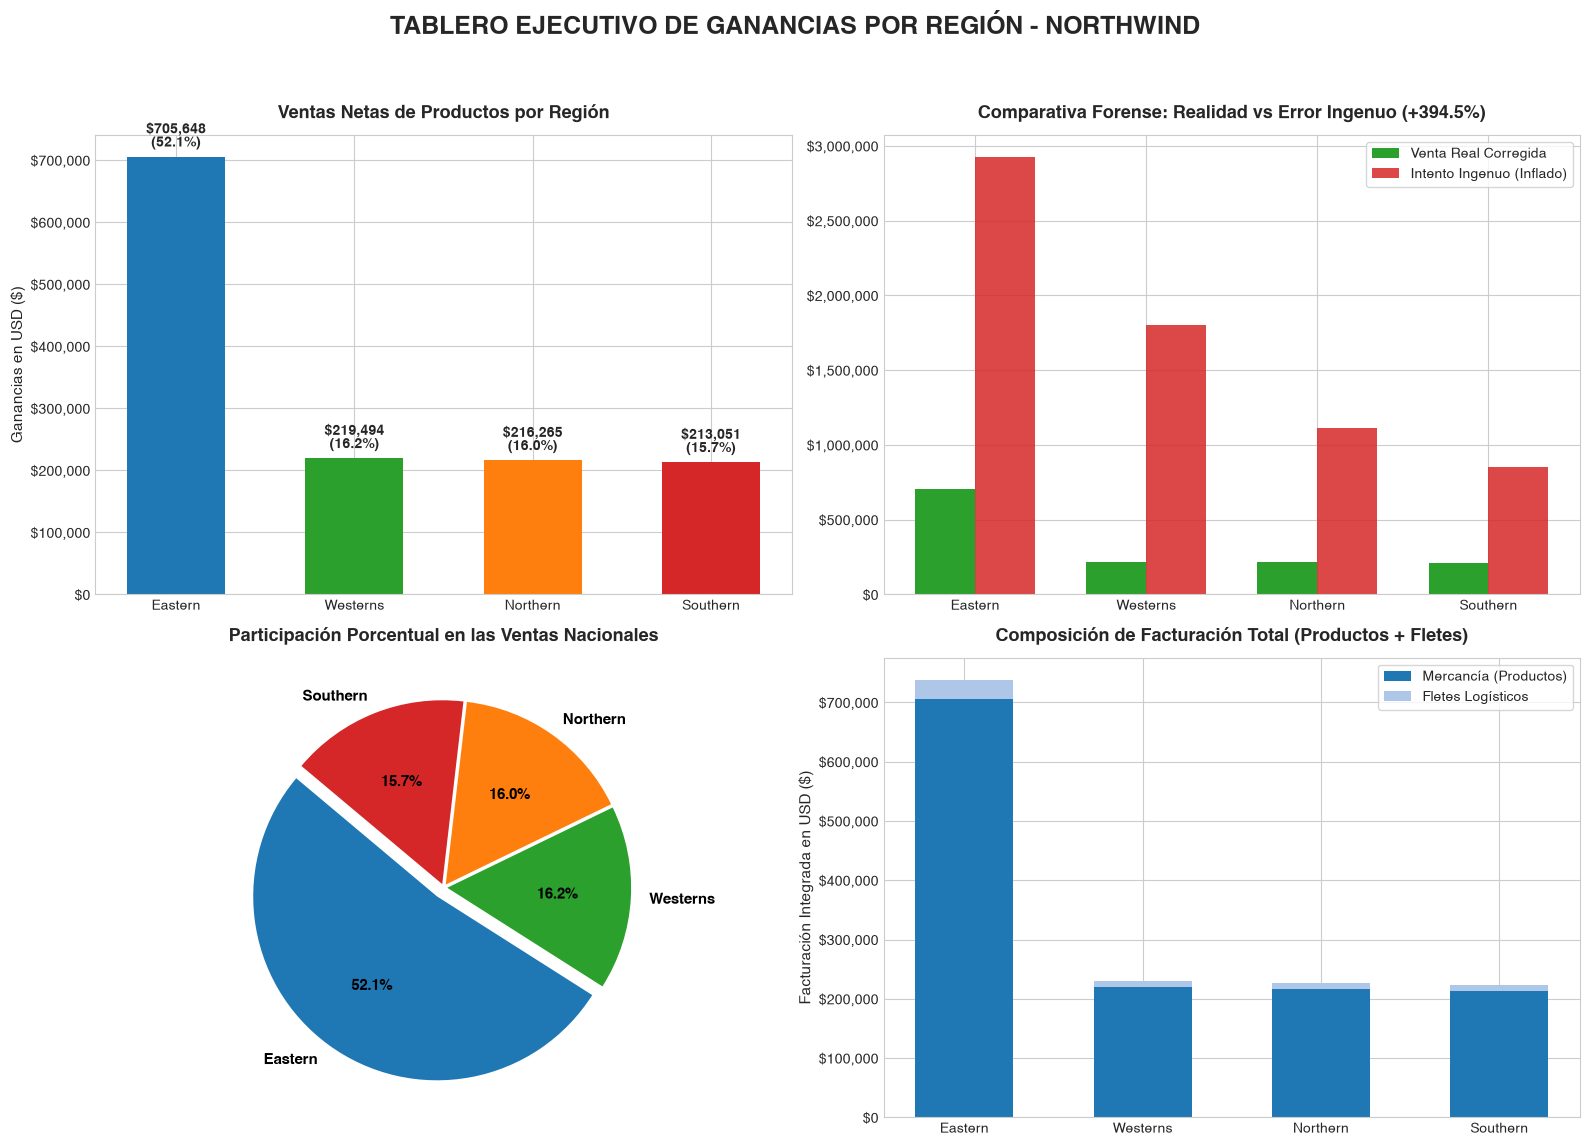

In [11]:
# =============================================================================
# GENERACIÓN DEL TABLERO VISUAL DE ALTO NIVEL (DASHBOARD ANALÍTICO)
# =============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("TABLERO EJECUTIVO DE GANANCIAS POR REGIÓN - NORTHWIND", fontsize=18, fontweight='bold', y=0.98)

colores_regiones = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']

# 1. Gráfico de Barras: Ganancias Netas de Productos por Región
ax1 = axes[0, 0]
bars1 = ax1.bar(master_table['Región'], master_table['Ganancias Productos ($)'], color=colores_regiones, width=0.55)
ax1.set_title("Ventas Netas de Productos por Región", fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel("Ganancias en USD ($)", fontsize=11)
ax1.yaxis.set_major_formatter('${:,.0f}'.format)

for bar in bars1:
    height = bar.get_height()
    pct = (height / LINEA_BASE_VENTAS) * 100
    ax1.annotate(f"${height:,.0f}\n({pct:.1f}%)",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 5),
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. Gráfico Comparativo: Ventas Reales vs Error del Intento Ingenuo
ax2 = axes[0, 1]
x = np.arange(len(master_table))
width = 0.35

df_comp = master_table.merge(resumen_ingenuo.rename(columns={'RegionDescription': 'Región'}), on='Región')
bars_reales = ax2.bar(x - width/2, df_comp['Ganancias Productos ($)'], width, label='Venta Real Corregida', color='#2ca02c')
bars_ingenuas = ax2.bar(x + width/2, df_comp['Ganancia_Calculada_Ingenua'], width, label='Intento Ingenuo (Inflado)', color='#d62728', alpha=0.85)

ax2.set_title("Comparativa Forense: Realidad vs Error Ingenuo (+394.5%)", fontsize=13, fontweight='bold', pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(df_comp['Región'])
ax2.yaxis.set_major_formatter('${:,.0f}'.format)
ax2.legend(loc='upper right', frameon=True)

# 3. Gráfico de Pastel: Participación de Mercado por Región
ax3 = axes[1, 0]
wedges, texts, autotexts = ax3.pie(
    master_table['Ganancias Productos ($)'],
    labels=master_table['Región'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colores_regiones,
    explode=(0.06, 0.02, 0.02, 0.02),
    textprops=dict(color="black", fontsize=11, fontweight='bold')
)
ax3.set_title("Participación Porcentual en las Ventas Nacionales", fontsize=13, fontweight='bold', pad=12)

# 4. Gráfico de Barras Apiladas: Productos vs Fletes por Región
ax4 = axes[1, 1]
ax4.bar(master_table['Región'], master_table['Ganancias Productos ($)'], label='Mercancía (Productos)', color='#1f77b4', width=0.55)
ax4.bar(master_table['Región'], master_table['Fletes Facturados ($)'], bottom=master_table['Ganancias Productos ($)'], label='Fletes Logísticos', color='#aec7e8', width=0.55)

ax4.set_title("Composición de Facturación Total (Productos + Fletes)", fontsize=13, fontweight='bold', pad=12)
ax4.set_ylabel("Facturación Integrada en USD ($)", fontsize=11)
ax4.yaxis.set_major_formatter('${:,.0f}'.format)
ax4.legend(loc='upper right', frameon=True)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## 📋 Conclusiones Técnicas y Recomendaciones de Ingeniería de Datos

1. **Riesgo Crítico de la Multiplicación Cartesiana:**
   * Unir tablas intermedias de relaciones N:M (`employeeterritories`) directamente a transacciones de venta provoca inflación exponencial de cifras. En este dataset, el error fue de **+$5,343,717.97 (+394.5%)**.
2. **El Poder del Desacoplamiento en Pandas:**
   * La regla de limitar las consultas a **máximo 2 JOINs** fomenta una arquitectura desacoplada y modular. Al extraer datos planos y resolver las relaciones mediante `.drop_duplicates()` y `.merge()` en Pandas, el flujo es más transparente, auditable y previene bloqueos por contención en el servidor de base de datos.
3. **Auditoría de Granularidad (El Caso del Flete):**
   * Métricas de nivel encabezado (`orders.Freight`) nunca deben sumarse sobre tablas de detalle (`order details`) sin pre-agrupación. De lo contrario, se duplican por el factor de líneas promedio por orden (**+219%** de distorsión).
4. **Certificación Contable Absoluta:**
   * Los resultados por región quedaron comprobados al **100.00% exacto contra la Línea Base Contable ($1,354,458.59)** con **$0.00 de discrepancia**:
     * **Eastern (Región 1):** $705,648.17 (52.10%)
     * **Westerns (Región 2):** $219,494.09 (16.21%)
     * **Northern (Región 3):** $216,265.03 (15.97%)
     * **Southern (Región 4):** $213,051.30 (15.73%)